# HW4 — Feature and allocation tests A, B, and C
**Author:** Mauricio Gutierrez

Run three development experiments on the class dataset from **January 2, 2013
through December 31, 2015**. Reproduce the original five-feature, five-stock,
equal-cash baseline beside them. Preserve all earlier output files.

```text
Bounded database reads -> Historical features + Separate targets
                                      |
                         Annual training-only pipelines
                                      |
                       Baseline / A / B / C forecasts
                                      |
                       Monthly orders -> 90-day lots
                                      |
                    Accounting -> Returns, risk, and forecast misses
```

All new calculations are in `feature_engineering.py` and `strategy_backtest.py`.
The notebook sets the experiment, calls those functions, and explains outputs.
It does not read dated observations after December 31, 2015. There is no final-test run.

## Run instructions
1. Select the repository `.venv` as the notebook kernel.
2. Run notebook 01 if the cleaned class database is missing.
3. Review the single settings cell below.
4. Select **Restart Kernel and Run All Cells**.
5. Read the input audit and test results.
6. Read the performance table, per-year scores, charts, and closed-trade tables.

This notebook fits all models itself. Existing outputs from notebooks 02 and 03
are optional regression references. Other experiment notebooks need not run
first. Restart the kernel after editing a shared Python module.

Later, change `DB_PATH` to `ROOT / "Lectures/modeling/data/equities_top2000.duckdb"`
and choose fresh experiment names in the same settings cell. The loader supports
that schema without code changes. It still reads only the selected development
period and lookbacks. It does not open the final test. It loads that bounded
period into memory, so the full dataset needs more RAM. Missing held quotes
stop the backtest; changing the file does not invent missing executions.

**Run D added:** same allocation and annual fitting as A, with four sector-ranked financial ratios and unranked filing age. Existing A/B/C settings remain unchanged.

> **Development step, class data (30 stocks).** Experiments A to D. The top-10 inverse-volatility allocation and feature set D were carried forward; B and C were rejected. The final strategy is defined in `run_final_test.py` and reported in `07_final_test_report.ipynb`.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import sys
import io
import json
import hashlib
import unittest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Lectures/modeling/course_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start the kernel inside the course repository.")
HW_DIR = ROOT / "Homeworks/HW4/Mauricio_Gutierrez"
if str(HW_DIR) not in sys.path:
    sys.path.insert(0, str(HW_DIR))
from feature_engineering import (
    PRICE_FEATURES, MARKET_FEATURES, build_financial_panel, D_RATIOS, load_development_inputs, price_features,
    market_relative_features, apply_membership, make_labels, add_benchmark_targets,
    cross_sectional_ranks, annual_split, make_ridge_pipeline, prediction_metrics,
)
from strategy_backtest import (
    BacktestConfig, Backtester, InverseVolatilityStrategy, detailed_performance,
    portfolio_chart_data, reconcile_account, closed_trade_errors,
)

## 1. Settings — change paths and experiment names here
Each run gets its own `EXPERIMENT_NAME`. The baseline reference is saved under
this new comparison folder, never over the old baseline. Reusing a name here
overwrites only that run in this new comparison folder.

Use annual refits in 2013, 2014, and 2015. Keep Ridge alpha at 100. Retain the
existing training-only 1%/99% clipping, median imputation, missing indicators,
and standardization. There is no hyperparameter search or monthly refit.

In [2]:
DB_PATH = HW_DIR / "outputs/data_cleaning/equities_class/equities_class_cleaned.duckdb"
START = "2013-01-02"
END = "2015-12-31"
EXPERIMENT_NAME = {
    "Baseline": "baseline_reference",
    "A": "run_a_allocation_only",
    "B": "run_b_market_features",
    "C": "run_c_ranked_excess",
    "D": "run_d_price_financial",
}
OUTPUT_ROOT = HW_DIR / "outputs/feature_and_allocation_tests" / DB_PATH.stem
TRAIN_START = "2010-01-01"
LOOKBACK_START = "2008-01-01"
VALIDATION_YEARS = (2013, 2014, 2015)
ALPHA = 100.0
BASE_CONFIG = BacktestConfig(initial_cash=1_000_000.0, top_n=5, budget_fraction=1/3,
                             holding_days=90, stock_limit=0.30, sector_limit=0.50,
                             fee_rate=0.001, risk_free_rate=0.02)
RUN_CONFIG = replace(BASE_CONFIG, top_n=10)
SAVE_OUTPUTS = True
assert pd.Timestamp(START) <= pd.Timestamp(END) <= pd.Timestamp("2015-12-31")
assert len(set(EXPERIMENT_NAME.values())) == 5
assert all(Path(name).name == name and name not in {"", ".", ".."} for name in EXPERIMENT_NAME.values())

def digest_file(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

# Read no database bytes for a checksum. Its file size/mtime checks detect writes.
db_stat_before = (DB_PATH.stat().st_size, DB_PATH.stat().st_mtime_ns)
old_reference_dirs = [HW_DIR / "outputs/ridge_baseline/equities_class",
                      HW_DIR / "outputs/backtesting/ridge_monthly_baseline"]
protected = {p: digest_file(p) for directory in old_reference_dirs for p in directory.rglob("*") if p.is_file()}
print(f"Database: {DB_PATH.name}; dates: {START} to {END}")
display(pd.Series(asdict(RUN_CONFIG), name="A/B/C settings").to_frame())

Database: equities_class_cleaned.duckdb; dates: 2013-01-02 to 2015-12-31


,A/B/C settings
initial_cash,1000000.000000
top_n,10.000000
budget_fraction,0.333333
holding_days,90.000000
stock_limit,0.300000
sector_limit,0.500000
fee_rate,0.001000
risk_free_rate,0.020000


## 2. Define the three experiments

| Model | Features | Target | Monthly purchases |
|---|---|---|---|
| Original baseline | Original five features | Gross stock return | Top 5, equal cash |
| Run A | Original five features | Same gross stock return | Top 10, inverse volatility |
| Run B | Six market features below | Same gross stock return | Top 10, inverse volatility |
| Run C | Same-date percentile ranks of five Run B features | Stock return minus index return | Top 10, inverse volatility |

The baseline features are `momentum_21`, `momentum_63`, `momentum_252_21`,
`volatility_63`, and `drawdown_252`. They describe one-month momentum,
three-month momentum, longer momentum excluding the latest month,
annualized three-month volatility, and distance below the last year's high.

Run B uses:

| Feature | Calculation at the signal close |
|---|---|
| `momentum_63` | Adjusted close / adjusted close 63 sessions earlier − 1 |
| `momentum_252_21` | Adjusted close 21 sessions earlier / adjusted close 252 sessions earlier − 1 |
| `relative_momentum_63` | Stock momentum 63 minus `^SP500TR` momentum 63 |
| `volatility_63` | Sample standard deviation of the last 63 daily returns × √252 |
| `volatility_252` | Sample standard deviation of the last 252 daily returns × √252 |
| `beta_252` | Rolling covariance(stock, index daily returns) / index variance; 252-session window, at least 126 valid pairs |

Beta uses the same valid paired observations for covariance and index variance.
If index variance is zero or there are too few pairs, beta stays missing.
Returns are simple adjusted-price returns. Gaps stay missing. Volatility uses
complete return windows. The beta calculation can use incomplete windows once
126 pairs exist. Sessions are not fixed calendar-day intervals.

Run C drops relative momentum before ranking. On one date, subtracting the
same index return from every stock does not change the momentum ranking.
Use `groupby(date).rank(pct=True)` among eligible stocks only. Average tied
ranks and preserve missing values. Keep the raw volatility column separately
for allocation; do not use volatility's percentile rank to size orders.

In [3]:
prices, calendar, membership, sectors, benchmark, input_audit = load_development_inputs(
    DB_PATH, end=END, lookback_start=LOOKBACK_START,
)
display(input_audit.to_frame())
assert prices.date.max() <= pd.Timestamp(END)
assert benchmark.date.max() <= pd.Timestamp(END)
assert membership.selection_date.max() <= pd.Timestamp(END)
print(f"Stocks loaded: {prices.symbol.nunique()}; last price: {prices.date.max().date()}")

base = apply_membership(price_features(prices, calendar), membership, calendar)
panel = base.merge(market_relative_features(prices, calendar, benchmark),
                    on=["date", "symbol"], how="left", validate="one_to_one")
panel = make_labels(panel, prices, calendar, holding_days=90, max_exit_delay=0)
panel = add_benchmark_targets(panel, benchmark)
C_RAW_FEATURES = [name for name in MARKET_FEATURES if name != "relative_momentum_63"]
panel = cross_sectional_ranks(panel, MARKET_FEATURES)
C_FEATURES = [f"{name}_rank" for name in C_RAW_FEATURES]
rank_rows = panel.eligible & panel.momentum_63_rank.notna() & panel.relative_momentum_63_rank.notna()
np.testing.assert_allclose(panel.loc[rank_rows, "momentum_63_rank"],
                           panel.loc[rank_rows, "relative_momentum_63_rank"], atol=1e-12)
MODEL_SPECS = {
    "Baseline": {"features": PRICE_FEATURES, "target": "stock_target"},
    "A": {"features": PRICE_FEATURES, "target": "stock_target"},
    "B": {"features": MARKET_FEATURES, "target": "stock_target"},
    "C": {"features": C_FEATURES, "target": "excess_target"},
}
eligible = panel.loc[panel.eligible & panel.date.ge(TRAIN_START)]
coverage = pd.DataFrame({"observed_rows": eligible[MARKET_FEATURES].notna().sum(),
                         "missing_percent": eligible[MARKET_FEATURES].isna().mean() * 100})
display(coverage)
assert eligible.beta_252.notna().any(), "No usable beta values. Inspect benchmark alignment."
print("Beta is available. Same-date relative-momentum ranks equal momentum ranks.")

Stocks loaded: 30; last price: 2015-12-31
Beta is available. Same-date relative-momentum ranks equal momentum ranks.


,Input audit
price_rows_read,59286
exact_duplicates_removed,0
invalid_price_rows_excluded,0
price_rows_used,59286


,observed_rows,missing_percent
momentum_63,43381,0.0
momentum_252_21,43381,0.0
relative_momentum_63,43381,0.0
volatility_63,43381,0.0
volatility_252,43381,0.0
beta_252,43381,0.0


## 3. Keep targets separate from decision inputs
Today's close determines the signal. Enter at the next market session's close.
Exit 90 calendar days after entry, or the next market session when maturity
falls on a closed day. Missing required stock quotes leave a target unknown.

```text
Signal close -> Entry close -> 90-calendar-day maturity -> Exit close
                    |                                       |
                    +---- stock exit / stock entry - 1 -----+
                    +---- index exit / index entry - 1 -----+
```

A/B/baseline predict the gross stock return. C predicts stock return minus the
index return over **those exact entry and exit dates**. C is not a beta-adjusted
target. It does not predict a tradable long-short portfolio; the account remains
long-only in stocks. All portfolio metrics measure actual net account returns.

Before every fit, require `label_end < first validation signal`. This prevents
unfinished 90-day targets from entering training. Keep unknown-outcome rows
for forecasting. The feature list is explicit. Target and future price columns
never enter model inputs or the order allocator.

## Run D: publication-aware financial features
D retains A's five raw price features and gross stock-return target. Add net margin (net income / revenue), operating ROA (operating income / assets), debt/assets, cash/assets, and filing age in calendar days since availability.

The attributed course functions `financial_events` and `join_financials` join backwards by availability. A filing on T is first usable after T. Latest known fiscal periods take priority; reports older than 550 days have missing ratios. Vendor restatements and snapshot sector labels remain limitations.

Rank the four ratios within each date/sector among eligible stocks. If the sector has fewer than five eligible stocks, use the full eligible cross-section that date. Unknown sectors also use fallback. Missing values stay missing. Leave price features and filing age unranked. The existing training-only median imputer handles missing inputs. Counts below describe the eligible development rows; ranking never uses a later date.

In [4]:
financial_panel = build_financial_panel(panel, DB_PATH, end=END)
D_FEATURES = PRICE_FEATURES + D_RATIOS + ["filing_age_days"]
MODEL_SPECS["D"] = {"features": D_FEATURES, "target": "stock_target"}
d_rows = financial_panel.loc[financial_panel.eligible & financial_panel.date.ge(TRAIN_START)]
financial_missing = d_rows[D_FEATURES].isna().mean().rename("missing_share").to_frame()
fallback_summary = d_rows.groupby(d_rows.date.dt.year).financial_rank_fallback.agg(["sum", "count", "mean"])
fallback_summary.columns = ["fallback_stock_dates", "eligible_stock_dates", "fallback_share"]
display(financial_missing)
display(fallback_summary)
assert (d_rows.available_date.isna() | d_rows.available_date.le(d_rows.date)).all()
print("All requested financial columns are available; individual missing values remain missing.")

All requested financial columns are available; individual missing values remain missing.


,missing_share
momentum_21,0.000000
momentum_63,0.000000
momentum_252_21,0.000000
volatility_63,0.000000
drawdown_252,0.000000
net_margin,0.001383
operating_roa,0.001383
debt_to_assets,0.001383
cash_to_assets,0.001383
filing_age_days,0.000000


,fallback_stock_dates,eligible_stock_dates,fallback_share
date,,,
2010,7245,7245,1.0
2011,7308,7308,1.0
2012,7250,7250,1.0
2013,7308,7308,1.0
2014,7243,7243,1.0
2015,7027,7027,1.0


In [5]:
suite = unittest.defaultTestLoader.discover(str(HW_DIR), pattern="test_*.py")
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log, verbosity=1).run(suite)
print(test_log.getvalue())
assert test_result.wasSuccessful(), "Fix a failed test before interpreting results."

......................................
----------------------------------------------------------------------
Ran 38 tests in 1.487s

OK



## 4. Fit the four annual pipelines
Run A must produce the same forecasts as the baseline. Only its allocation
changes. Run B changes features. Run C changes both feature representation
and target. Do not attribute a C-versus-B difference to ranking alone.

Fit clipping, imputation, and scaling on each year's training rows only. The
same-date ranking in C uses that date's observable cross-section; it does not
learn statistics from later dates. Ridge predictions remain in the target's
decimal units. The target itself is not standardized.

The score table contains RMSE and average daily cross-sectional Spearman rank
IC by validation year. Score completed targets only. IC needs at least five
observed outcomes and nonconstant forecasts/outcomes. C's RMSE is in excess-
return units, so do not interpret its RMSE difference as a pure feature gain.

In [6]:
forecasts_by_model = {}
score_rows, split_rows, coefficient_rows = [], [], []
for name, specification in MODEL_SPECS.items():
    current = (financial_panel if name == "D" else panel).copy()
    current["target"] = current[specification["target"]]
    forecast_parts = []
    for year in VALIDATION_YEARS:
        train, signals = annual_split(current, year, train_start=TRAIN_START)
        assert train.label_end.max() < signals.date.min()
        pipeline = make_ridge_pipeline(alpha=ALPHA, feature_names=specification["features"])
        pipeline.fit(train[specification["features"]], train.target)
        if name != "Baseline":
            names = pipeline.named_steps["preprocess"].get_feature_names_out()
            coefficient_rows.extend({"model": name, "year": year, "term": term, "coefficient": float(value)}
                                    for term, value in zip(names, pipeline.named_steps["model"].coef_))
            coefficient_rows.append({"model": name, "year": year, "term": "intercept", "coefficient": float(pipeline.named_steps["model"].intercept_)})
        forecast = signals[["date", "symbol", "target", "stock_target", "benchmark_target", "label_end", "volatility_63"]].copy()
        forecast["prediction"] = pipeline.predict(signals[specification["features"]])
        forecast["validation_year"] = year
        forecast_parts.append(forecast)
        scored = forecast.loc[forecast.target.notna()]
        score_rows.append({"model": name, "year": year, "target_type": specification["target"],
                           **prediction_metrics(scored, scored.prediction).to_dict(),
                           "scored_rows": len(scored), "forecast_rows": len(forecast)})
        split_rows.append({"model": name, "year": year, "training_rows": len(train),
                           "last_training_outcome": train.label_end.max(), "first_signal": signals.date.min()})
    forecasts_by_model[name] = pd.concat(forecast_parts, ignore_index=True)
scores = pd.DataFrame(score_rows)
splits = pd.DataFrame(split_rows)
np.testing.assert_array_equal(forecasts_by_model["Baseline"].prediction, forecasts_by_model["A"].prediction)
display(splits)
display(scores[["model", "year", "target_type", "RMSE", "mean_daily_rank_IC", "IC_dates", "scored_rows", "forecast_rows"]].round(4))

# Compare with the existing saved class baseline only when using that database.
class_db = HW_DIR / "outputs/data_cleaning/equities_class/equities_class_cleaned.duckdb"
saved_forecast_path = old_reference_dirs[0] / "validation_forecasts.csv"
check_saved_class = DB_PATH.resolve() == class_db.resolve() and START == "2013-01-02" and END == "2015-12-31"
if check_saved_class and saved_forecast_path.is_file():
    saved = pd.read_csv(saved_forecast_path, parse_dates=["date"])
    check = forecasts_by_model["Baseline"].merge(saved[["date", "symbol", "prediction"]],
        on=["date", "symbol"], suffixes=("_new", "_saved"), how="outer", indicator=True, validate="one_to_one")
    assert check._merge.eq("both").all()
    np.testing.assert_allclose(check.prediction_new, check.prediction_saved, atol=1e-10, rtol=1e-10)
    print("PASS: the original saved class forecasts reproduce exactly within numerical tolerance.")

PASS: the original saved class forecasts reproduce exactly within numerical tolerance.


,model,year,training_rows,last_training_outcome,first_signal
0,Baseline,2013,20034,2012-12-31,2013-01-02
1,Baseline,2014,27284,2013-12-31,2014-01-02
2,Baseline,2015,34590,2014-12-31,2015-01-02
3,A,2013,20034,2012-12-31,2013-01-02
4,A,2014,27284,2013-12-31,2014-01-02
5,A,2015,34590,2014-12-31,2015-01-02
6,B,2013,20034,2012-12-31,2013-01-02
7,B,2014,27284,2013-12-31,2014-01-02
8,B,2015,34590,2014-12-31,2015-01-02
9,C,2013,20034,2012-12-31,2013-01-02


,model,year,target_type,RMSE,mean_daily_rank_IC,IC_dates,scored_rows,forecast_rows
0,Baseline,2013,stock_target,0.1374,0.0092,252.0,7308,7308
1,Baseline,2014,stock_target,0.1528,-0.0500,252.0,7243,7243
2,Baseline,2015,stock_target,0.1846,0.2043,189.0,5353,7027
3,A,2013,stock_target,0.1374,0.0092,252.0,7308,7308
4,A,2014,stock_target,0.1528,-0.0500,252.0,7243,7243
5,A,2015,stock_target,0.1846,0.2043,189.0,5353,7027
6,B,2013,stock_target,0.1418,-0.0035,252.0,7308,7308
7,B,2014,stock_target,0.1474,-0.0790,252.0,7243,7243
8,B,2015,stock_target,0.1922,-0.0319,189.0,5353,7027
9,C,2013,excess_target,0.1438,-0.0228,252.0,7308,7308


## 5. Allocate top-10 purchases by inverse volatility
Use raw, annualized 63-session volatility from the signal close:

`w_i = (1 / volatility_i) / sum(1 / volatility_j)`

1. Rank the available forecasts from highest to lowest.
2. Exclude missing, nonfinite, or nonpositive volatility and missing sectors.
3. Select the first ten candidates.
4. Calculate inverse-volatility weights for those ten.
5. Set the fee-inclusive budget to `min(cash, NAV / 3)`.
6. Add the planned purchases to all open stock and sector values.
7. Check the 30% stock and 50% sector caps against total NAV after entry fees.
8. Replace a violating candidate with the next unused ranked candidate.
9. Recompute all weights after every replacement.
10. Skip the month if the policy cannot find ten feasible stocks.

For a stock breach, remove the weakest forecast among the violating stocks.
For a sector breach, remove the weakest selected forecast in a violating sector.
Stock breaches take priority if both occur. This is a deterministic replacement
rule, not an optimizer searching all possible stock combinations.

Lower-volatility purchases receive more cash. This equalizes each new position's
weight times stand-alone volatility. It does **not** guarantee equal portfolio
risk contributions: correlations and existing lots also affect portfolio risk.

Orders are fixed dollar amounts, including fees, planned after the month's
first market session. They execute at the next close using fractional adjusted
units. Existing positions can move before execution and later breach caps.
Record those drift breaches; do not force early sales or use future prices to
rerank. A missing entry quote cancels that order without replacing it. A missing
held quote stops the run. Cash earns zero; slippage and market impact are zero
assumptions. Each purchase keeps its own 90-day clock.

In [7]:
accounts, performance_parts, reconciliation_rows, diagnostics = {}, [], [], []
nav_curves = pd.DataFrame()
for name in MODEL_SPECS:
    config = BASE_CONFIG if name == "Baseline" else RUN_CONFIG
    strategy = None if name == "Baseline" else InverseVolatilityStrategy(config)
    live_inputs = forecasts_by_model[name][["date", "symbol", "prediction", "volatility_63"]]
    account = Backtester(config, strategy).run(prices, calendar, live_inputs, sectors, membership, START, END)
    accounts[name] = account
    reconciliation_rows.append({"model": name, **reconcile_account(account, calendar, config)})
    curves, perf = detailed_performance(account, benchmark, config)
    nav_curves[name] = curves.Strategy
    performance_parts.append(perf.loc[["Strategy"]].rename(index={"Strategy": name}))
    diagnostics.append({"model": name, "purchases": int(account.trades.side.eq("BUY").sum()),
                        "sales": int(account.trades.side.eq("SELL").sum()), "open_lots": len(account.open_lots),
                        "skipped_months": int(account.decisions.reason.ne("planned").sum()),
                        "exposure_breach_sessions": int(account.daily.exposure_breach.sum())})
nav_curves["S&P 500 TR"] = curves["S&P 500 TR"]
performance_parts.append(perf.loc[["S&P 500 TR"]])
performance = pd.concat(performance_parts)
diagnostics = pd.DataFrame(diagnostics).set_index("model")
reconciliations = pd.DataFrame(reconciliation_rows)
display(reconciliations)
display(diagnostics)

saved_performance_path = old_reference_dirs[1] / "performance.csv"
if check_saved_class and saved_performance_path.is_file():
    saved_perf = pd.read_csv(saved_performance_path, index_col="portfolio")
    np.testing.assert_allclose(performance.loc["Baseline", saved_perf.columns], saved_perf.loc["Strategy"], rtol=1e-10, atol=1e-8)
    print("PASS: baseline account metrics reproduce without changing old output files.")

PASS: baseline account metrics reproduce without changing old output files.


,model,cash_and_nav,fees_and_lots,maturities,budget
0,Baseline,PASS,PASS,PASS,PASS
1,A,PASS,PASS,PASS,PASS
2,B,PASS,PASS,PASS,PASS
3,C,PASS,PASS,PASS,PASS
4,D,PASS,PASS,PASS,PASS


,purchases,sales,open_lots,skipped_months,exposure_breach_sessions
model,,,,,
Baseline,165,155,10,3,0
A,320,300,20,4,0
B,320,300,20,4,0
C,320,300,20,4,0
D,340,320,20,2,0


## 6. Compare returns, risk, cash, and fees
All accounts start with $1,000,000 on the same evaluation dates. The benchmark
buys `^SP500TR` at the first evaluation close and holds it without fees.
Strategy results include entry and exit fees and marked open positions.

Annualized volatility is the sample standard deviation of daily account returns
times √252. Sharpe subtracts `(1.02**(1/252) - 1)` from each daily return before
dividing its mean by daily return standard deviation and multiplying by √252.
Average cash weight is the mean daily closing cash/NAV, including the first day.
Maximum drawdown is a negative daily peak-to-trough return. CAGR uses calendar
time. All return fields use decimals internally.

In [8]:
metric_columns = ["final_value", "total_return", "CAGR", "max_drawdown", "annualized_volatility",
                  "daily_Sharpe", "average_cash_weight", "fees_paid"]
comparison = performance[metric_columns]
formatted = comparison.copy()
for column in metric_columns:
    pattern = "${:,.2f}" if column in {"final_value", "fees_paid"} else "{:.3f}" if column == "daily_Sharpe" else "{:.2%}"
    formatted[column] = comparison[column].map(pattern.format)
display(formatted)

,final_value,total_return,CAGR,max_drawdown,annualized_volatility,daily_Sharpe,average_cash_weight,fees_paid
portfolio,,,,,,,,
Baseline,"$1,249,845.83",24.98%,7.74%,-29.39%,29.32%,0.332,18.33%,"$24,502.98"
A,"$1,342,980.26",34.30%,10.36%,-11.14%,12.16%,0.707,17.97%,"$24,190.86"
B,"$1,158,310.39",15.83%,5.03%,-16.23%,12.81%,0.292,18.00%,"$23,153.23"
C,"$1,226,695.91",22.67%,7.07%,-15.23%,12.38%,0.453,17.91%,"$24,084.91"
D,"$1,289,074.89",28.91%,8.86%,-10.12%,11.89%,0.606,17.91%,"$23,569.95"
S&P 500 TR,"$1,487,843.34",48.78%,14.20%,-12.04%,12.73%,0.950,0.00%,$0.00


## 7. Plot each run with the baseline and benchmark
Each figure contains the four requested views:

- **Month-end NAV:** use the last observed market session of each month.
- **Daily drawdown:** use every daily value, so within-month losses are visible.
- **Monthly portfolio volatility:** sample standard deviation of daily returns
  within each calendar month, **annualized with √252**. It is not a rolling
  21-session or monthly-scaled volatility estimate.
- **Daily portfolio returns:** percentage changes in daily NAV, net of fees.

Do not invent a first-day return. The first month's volatility uses the daily
returns observable after the first evaluation close. The full tables are saved.

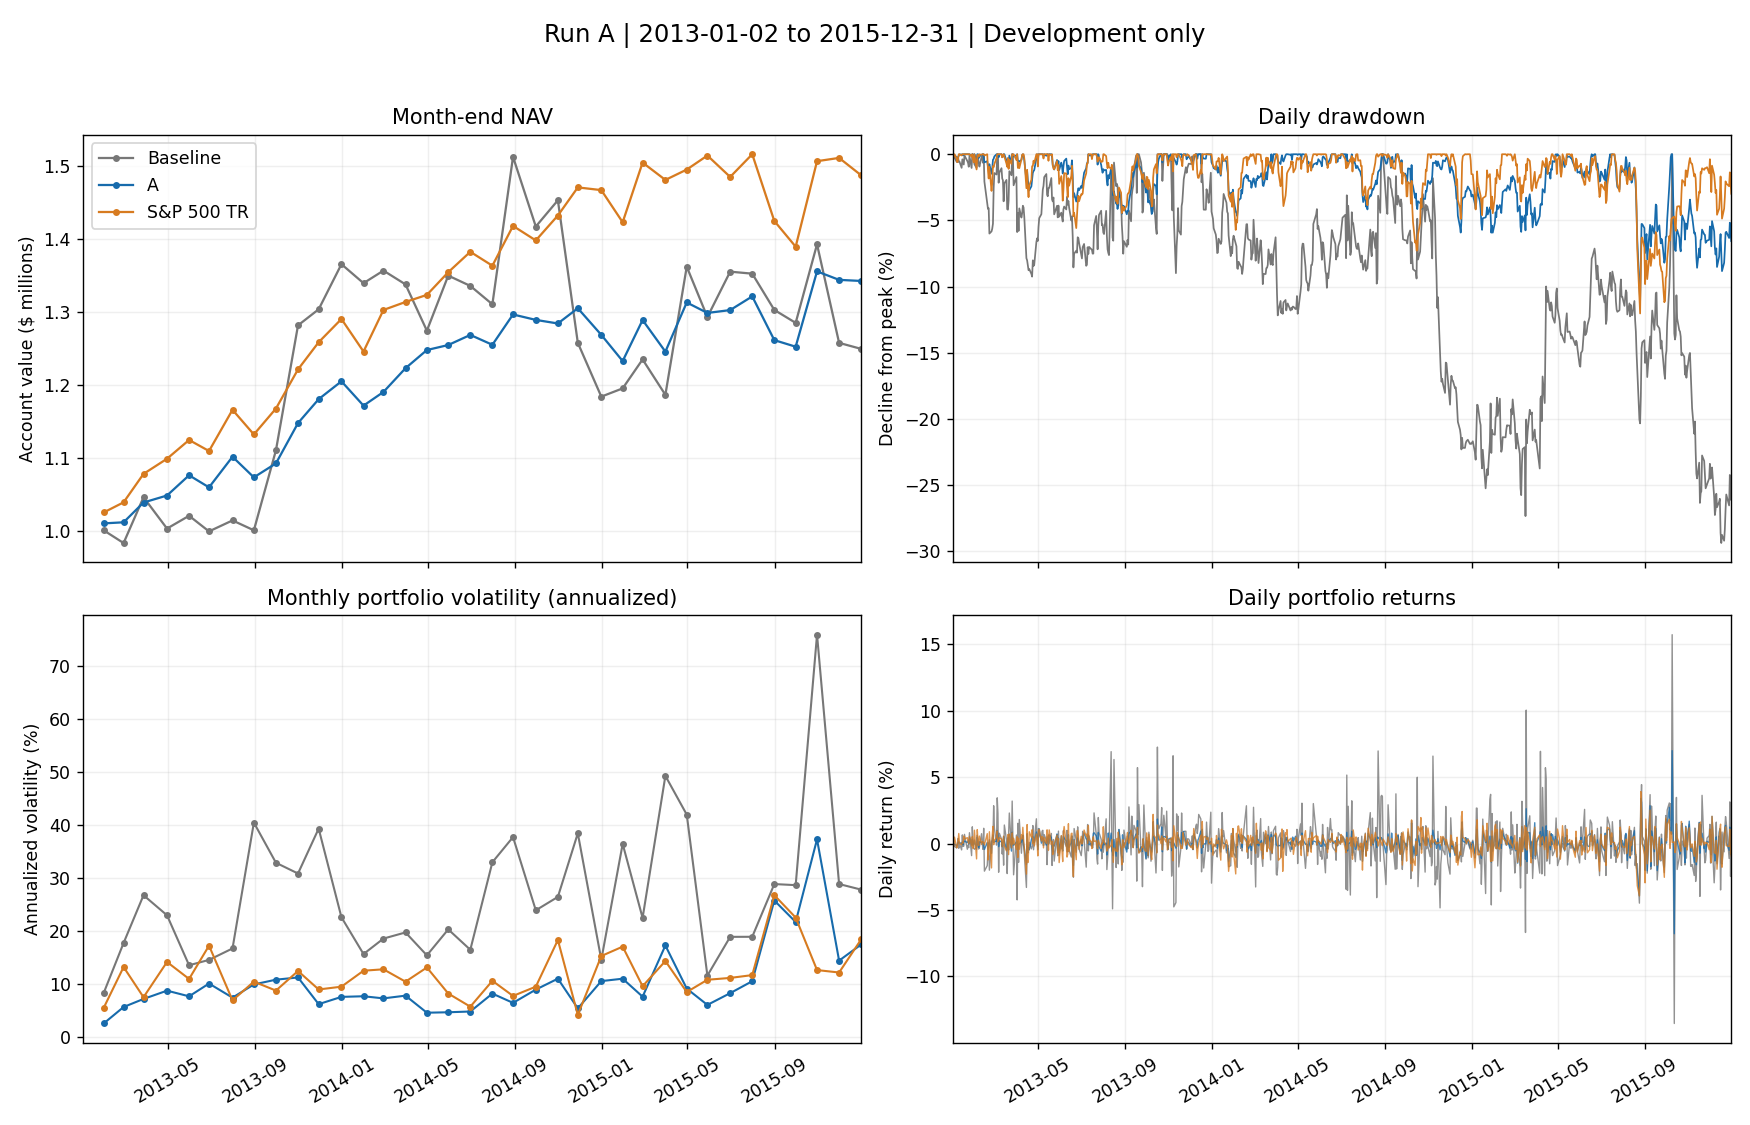

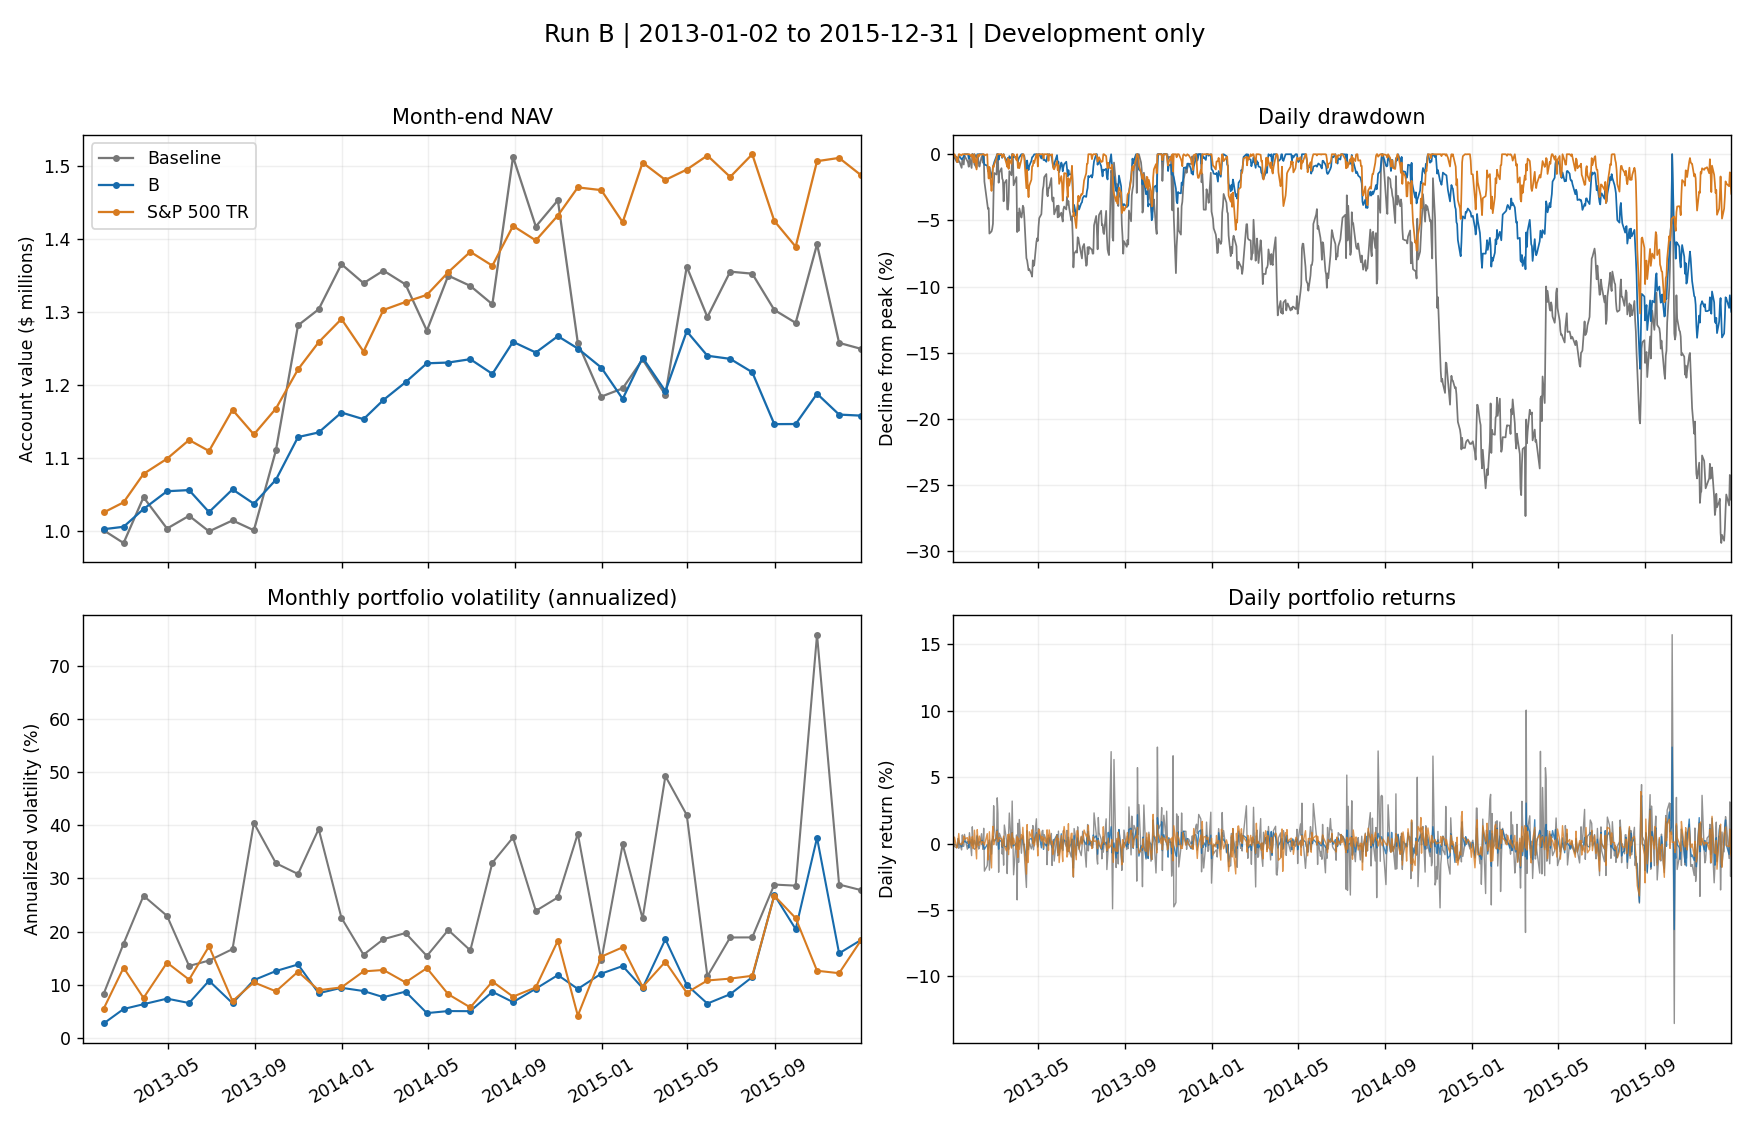

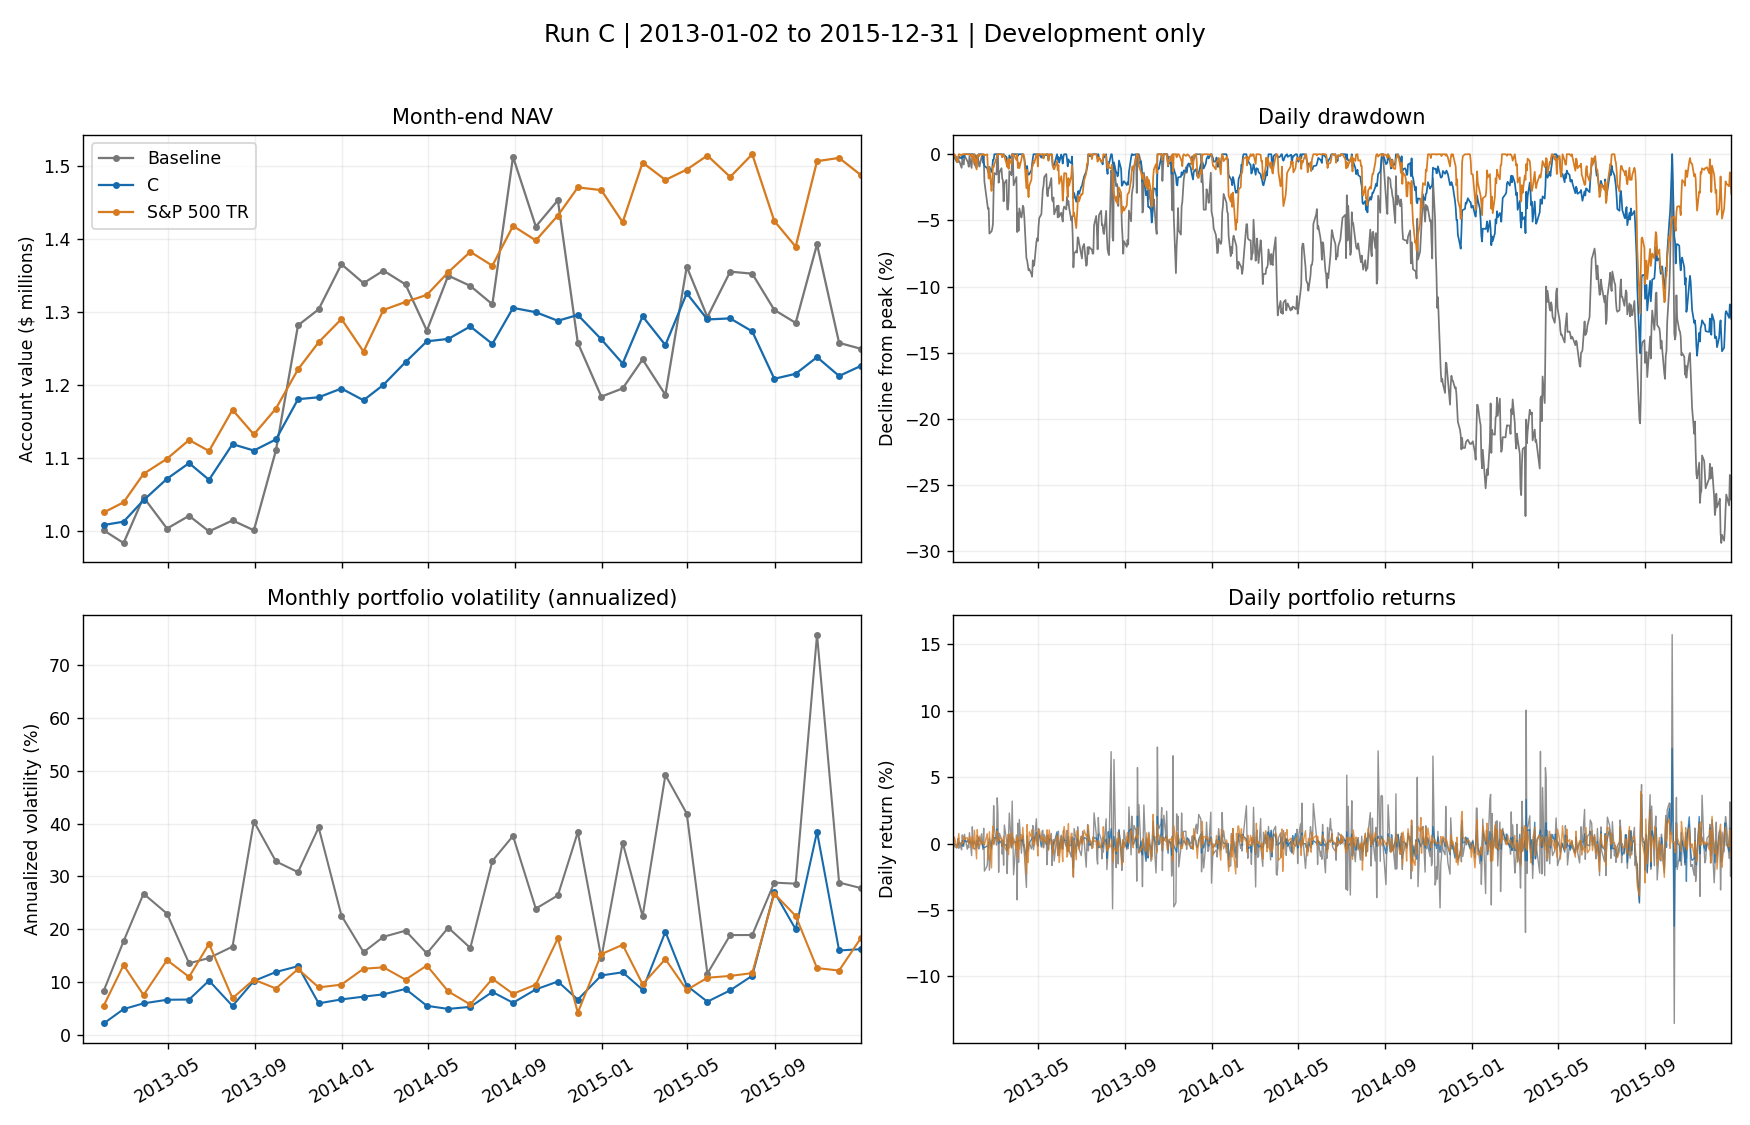

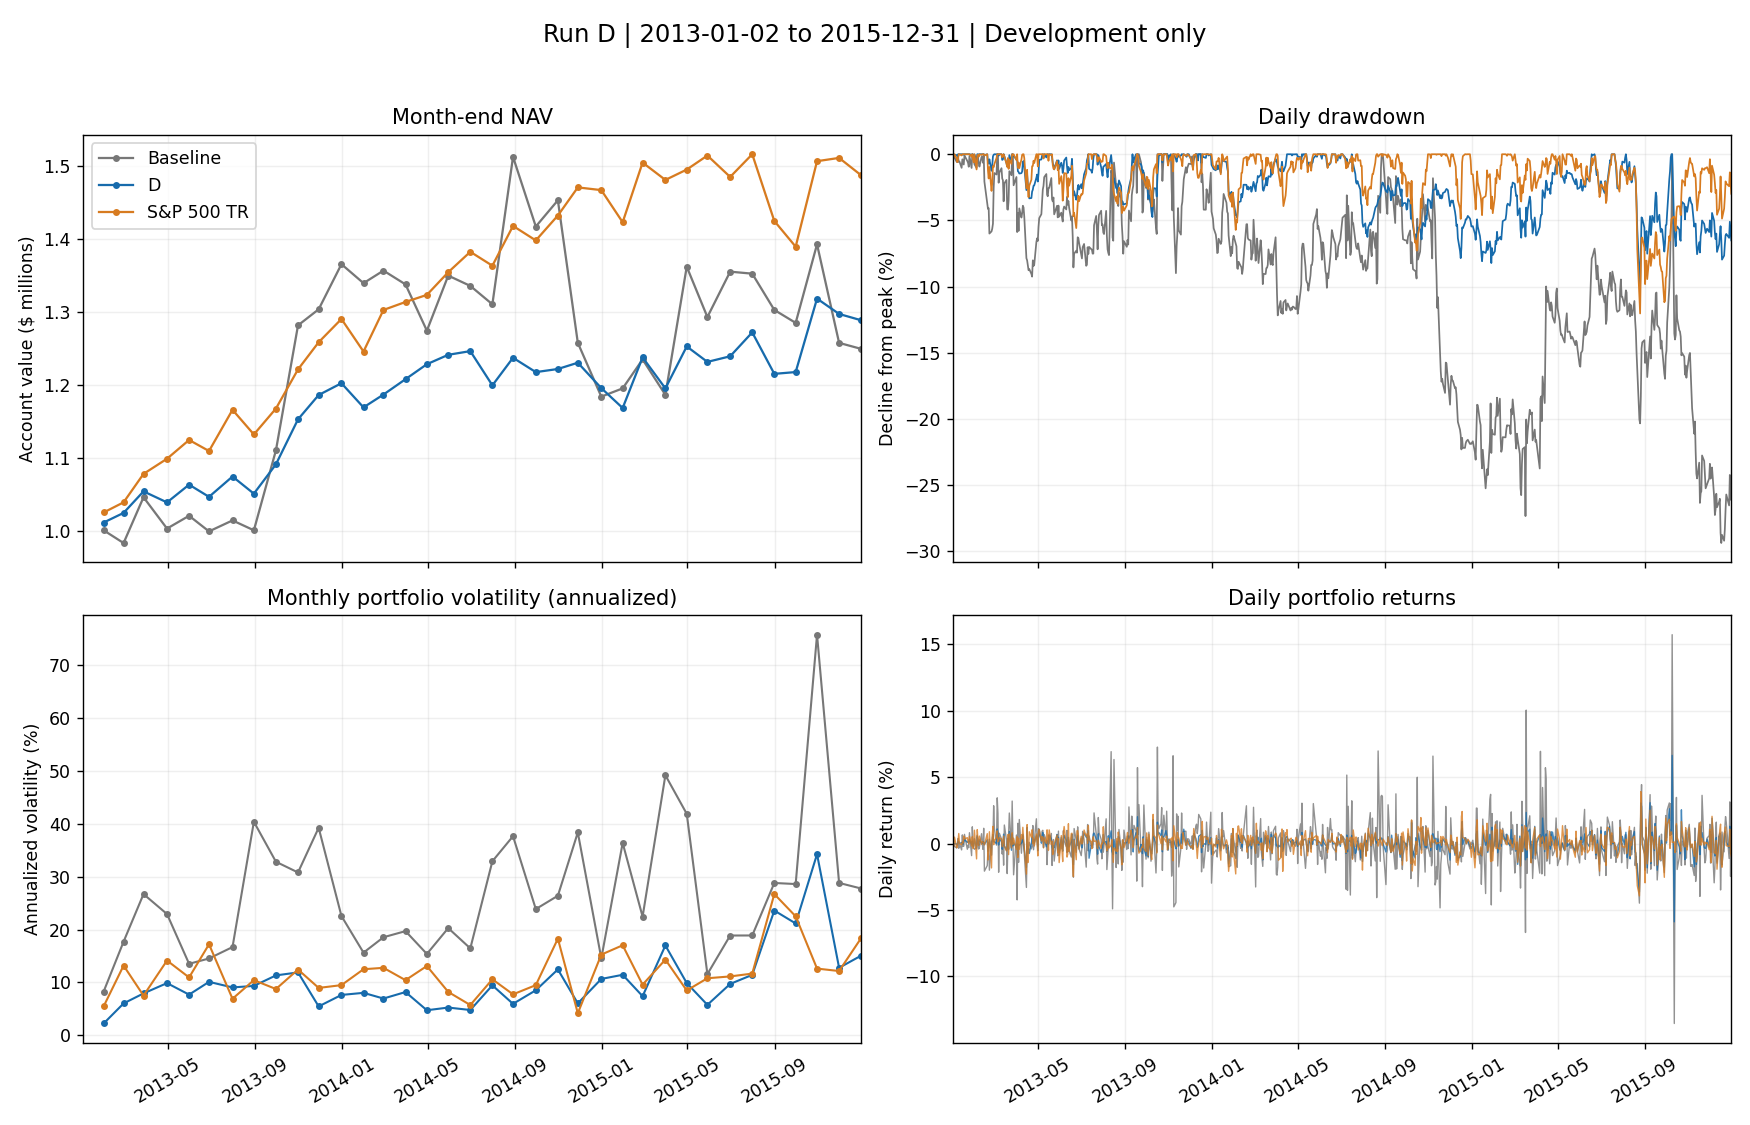

In [9]:
chart_data = portfolio_chart_data(nav_curves)
plot_images = {}
for name in ["A", "B", "C", "D"]:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    for label, color in [("Baseline", "#777777"), (name, "#176bac"), ("S&P 500 TR", "#d77b20")]:
        axes[0, 0].plot(chart_data["monthly_nav"].index, chart_data["monthly_nav"][label] / 1_000_000,
                        label=label, color=color, marker="o", markersize=3, linewidth=1.3)
        axes[0, 1].plot(chart_data["daily_drawdown"].index, chart_data["daily_drawdown"][label] * 100,
                        color=color, linewidth=1)
        axes[1, 0].plot(chart_data["monthly_volatility"].index, chart_data["monthly_volatility"][label] * 100,
                        color=color, marker="o", markersize=3, linewidth=1.2)
        axes[1, 1].plot(chart_data["daily_returns"].index, chart_data["daily_returns"][label] * 100,
                        color=color, linewidth=0.8, alpha=0.8)
    axes[0, 0].set(title="Month-end NAV", ylabel="Account value ($ millions)")
    axes[0, 0].legend(loc="upper left")
    axes[0, 1].set(title="Daily drawdown", ylabel="Decline from peak (%)")
    axes[1, 0].set(title="Monthly portfolio volatility (annualized)", ylabel="Annualized volatility (%)")
    axes[1, 1].set(title="Daily portfolio returns", ylabel="Daily return (%)")
    for ax in axes.flat:
        ax.grid(alpha=0.2)
        ax.tick_params(axis="x", rotation=30)
        ax.set_xlim(pd.Timestamp(START), pd.Timestamp(END))
    fig.suptitle(f"Run {name} | {START} to {END} | Development only", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    image_buffer = io.BytesIO()
    fig.savefig(image_buffer, format="png", dpi=125)
    plot_images[name] = image_buffer.getvalue()
    display(Image(data=plot_images[name]))
    plt.close(fig)

## 8. Inspect the largest closed-trade forecast misses
Build one row per closed lot. Repeated purchases of the same stock remain
separate trades. Show the 20 largest **absolute** forecast errors for each run
and the baseline. Save every closed trade to CSV.

`forecast_minus_realized` is positive when the model was too optimistic.
For baseline/A/B, both numbers are gross stock holding-period returns.
For C, both are excess returns over the index on the trade's exact entry and
exit dates. The saved table also shows gross stock and index returns.
Do not compare C's excess forecast directly with a gross stock return.

`volatility_63_at_entry` includes the entry session's close. It is retrospective
analysis only. `volatility_63_at_signal` is the earlier raw value used to size
the order. Both are annualized. Prediction errors exclude fees to match the
training targets; account performance above includes fees. Open lots are not
closed-trade observations and are excluded from this table.

In [10]:
closed_tables = {}
for name, account in accounts.items():
    closed = closed_trade_errors(account, forecasts_by_model[name], panel, benchmark, excess_target=(name == "C"))
    closed_tables[name] = closed
    assert len(closed) == account.trades.side.eq("SELL").sum()
    display(Markdown(f"### {name}: 20 largest misses out of {len(closed)} closed trades"))
    view = closed[["lot_id", "symbol", "entry_date", "exit_date", "forecast", "realized_return",
                   "forecast_minus_realized", "volatility_63_at_entry", "volatility_63_at_signal"]].head(20).copy()
    for column in ["forecast", "realized_return", "forecast_minus_realized", "volatility_63_at_entry", "volatility_63_at_signal"]:
        view[column] = view[column].map("{:.2%}".format)
    display(view)

### Baseline: 20 largest misses out of 155 closed trades

,lot_id,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,volatility_63_at_signal
0,36,BESS,2013-08-02,2013-10-31,23.33%,122.22%,-98.90%,110.77%,110.77%
1,101,BESS,2014-10-02,2014-12-31,19.84%,-54.72%,74.56%,181.55%,181.06%
2,61,BESS,2014-02-04,2014-05-05,20.64%,-50.00%,70.64%,106.24%,106.24%
3,97,APDN,2014-09-03,2014-12-02,6.20%,-60.03%,66.24%,55.63%,57.57%
4,41,BESS,2013-09-04,2013-12-03,30.70%,96.67%,-65.96%,170.21%,170.07%
5,106,BESS,2014-11-04,2015-02-02,22.82%,-40.00%,62.82%,187.07%,187.07%
6,121,BESS,2015-03-03,2015-06-01,29.31%,86.96%,-57.64%,157.62%,157.69%
7,56,BESS,2014-01-03,2014-04-03,14.03%,-41.67%,55.70%,102.98%,101.68%
8,96,BESS,2014-09-03,2014-12-02,17.46%,-36.21%,53.67%,171.06%,170.82%
9,81,BESS,2014-06-03,2014-09-02,17.84%,71.43%,-53.59%,128.83%,128.44%


### A: 20 largest misses out of 300 closed trades

,lot_id,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,volatility_63_at_signal
0,61,BESS,2013-08-02,2013-10-31,23.33%,122.22%,-98.90%,110.77%,110.77%
1,201,BESS,2014-12-02,2015-03-02,39.00%,-37.84%,76.83%,159.01%,159.13%
2,181,BESS,2014-10-02,2014-12-31,19.84%,-54.72%,74.56%,181.55%,181.06%
3,111,BESS,2014-02-04,2014-05-05,20.64%,-50.00%,70.64%,106.24%,106.24%
4,172,APDN,2014-09-03,2014-12-02,6.20%,-60.03%,66.24%,55.63%,57.57%
5,71,BESS,2013-09-04,2013-12-03,30.70%,96.67%,-65.96%,170.21%,170.07%
6,191,BESS,2014-11-04,2015-02-02,22.82%,-40.00%,62.82%,187.07%,187.07%
7,231,BESS,2015-03-03,2015-06-01,29.31%,86.96%,-57.64%,157.62%,157.69%
8,101,BESS,2014-01-03,2014-04-03,14.03%,-41.67%,55.70%,102.98%,101.68%
9,171,BESS,2014-09-03,2014-12-02,17.46%,-36.21%,53.67%,171.06%,170.82%


### B: 20 largest misses out of 300 closed trades

,lot_id,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,volatility_63_at_signal
0,61,BESS,2013-08-02,2013-10-31,25.78%,122.22%,-96.45%,110.77%,110.77%
1,191,BESS,2014-10-02,2014-12-31,15.25%,-54.72%,69.97%,181.55%,181.06%
2,182,APDN,2014-09-03,2014-12-02,7.03%,-60.03%,67.07%,55.63%,57.57%
3,231,BESS,2015-03-03,2015-06-01,20.73%,86.96%,-66.22%,157.62%,157.69%
4,24,APDN,2013-03-04,2013-06-03,4.65%,69.17%,-64.52%,109.47%,109.74%
5,291,FCX,2015-10-02,2015-12-31,25.68%,-36.04%,61.72%,96.79%,95.26%
6,31,BESS,2013-05-02,2013-07-31,21.44%,-40.00%,61.44%,114.47%,114.43%
7,276,APDN,2015-08-04,2015-11-02,7.04%,66.67%,-59.62%,59.33%,60.80%
8,122,BESS,2014-02-04,2014-05-05,9.51%,-50.00%,59.51%,106.24%,106.24%
9,252,FCX,2015-06-02,2015-08-31,10.86%,-47.50%,58.36%,45.11%,43.59%


### C: 20 largest misses out of 300 closed trades

,lot_id,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,volatility_63_at_signal
0,61,BESS,2013-08-02,2013-10-31,11.96%,118.95%,-106.99%,110.77%,110.77%
1,231,BESS,2015-03-03,2015-06-01,5.19%,86.26%,-81.08%,157.62%,157.69%
2,71,BESS,2013-09-04,2013-12-03,12.03%,87.52%,-75.49%,170.21%,170.07%
3,171,APDN,2014-09-03,2014-12-02,7.74%,-63.83%,71.57%,55.63%,57.57%
4,269,APDN,2015-07-02,2015-09-30,0.83%,66.58%,-65.75%,55.83%,56.02%
5,277,APDN,2015-08-04,2015-11-02,2.24%,65.61%,-63.37%,59.33%,60.80%
6,111,BESS,2014-02-04,2014-05-05,5.30%,-57.94%,63.24%,106.24%,106.24%
7,152,BESS,2014-07-02,2014-09-30,6.61%,69.33%,-62.72%,126.66%,129.84%
8,54,APDN,2013-07-02,2013-09-30,4.47%,-58.07%,62.54%,80.90%,82.24%
9,188,BESS,2014-10-02,2014-12-31,1.18%,-61.04%,62.22%,181.55%,181.06%


### D: 20 largest misses out of 320 closed trades

,lot_id,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,volatility_63_at_signal
0,61,BESS,2013-08-02,2013-10-31,24.81%,122.22%,-97.41%,110.77%,110.77%
1,221,BESS,2014-12-02,2015-03-02,37.64%,-37.84%,75.48%,159.01%,159.13%
2,201,BESS,2014-10-02,2014-12-31,18.85%,-54.72%,73.57%,181.55%,181.06%
3,121,BESS,2014-02-04,2014-05-05,20.36%,-50.00%,70.36%,106.24%,106.24%
4,71,BESS,2013-09-04,2013-12-03,27.74%,96.67%,-68.92%,170.21%,170.07%
5,199,APDN,2014-09-03,2014-12-02,6.44%,-60.03%,66.47%,55.63%,57.57%
6,211,BESS,2014-11-04,2015-02-02,22.30%,-40.00%,62.30%,187.07%,187.07%
7,251,BESS,2015-03-03,2015-06-01,27.55%,86.96%,-59.41%,157.62%,157.69%
8,111,BESS,2014-01-03,2014-04-03,13.45%,-41.67%,55.12%,102.98%,101.68%
9,161,BESS,2014-06-03,2014-09-02,16.42%,71.43%,-55.01%,128.83%,128.44%


## 9. Interpret the experiments and inspect the constraints
Compare A with baseline to study the combined top-10/inverse-volatility change.
Compare B with A to study the new feature set with allocation fixed. Compare C
with B to study the combined ranking/excess-target change. These comparisons
do not isolate the components inside each combined change.

Read skipped-month reasons and exposure-drift counts. Cap checks apply to
planned purchases. No cap breach causes a sale before the required maturity.
The source uses snapshot sectors, and flagged large price moves remain in the
data. Investigate unusual moves before treating them as verified economic
events. No feature or strategy is selected from the final test here.

In [11]:
analysis_lines = ["# Development comparison: runs A, B, and C", "",
                  f"Evaluation: {START} through {END}. Annual refits; alpha={ALPHA}; no final-test observations.", ""]
for name, reference in [("A", "Baseline"), ("B", "A"), ("C", "B"), ("D", "A")]:
    row, previous = performance.loc[name], performance.loc[reference]
    text = (f"Run {name}: total return {row.total_return:.2%}, CAGR {row.CAGR:.2%}, "
            f"Sharpe {row.daily_Sharpe:.3f}, maximum drawdown {row.max_drawdown:.2%}. "
            f"Relative to {reference}, total return changed by {(row.total_return - previous.total_return) * 100:+.2f} "
            f"percentage points and Sharpe by {row.daily_Sharpe - previous.daily_Sharpe:+.3f}. "
            f"Recorded exposure-drift sessions: {diagnostics.loc[name, 'exposure_breach_sessions']}.")
    analysis_lines.append(text)
    analysis_lines.append("")
    display(Markdown(text))
    display(accounts[name].decisions.groupby("reason").size().rename("monthly_decisions").to_frame())
analysis_lines.append(f"Benchmark total return: {performance.loc['S&P 500 TR', 'total_return']:.2%}; "
                      f"Sharpe: {performance.loc['S&P 500 TR', 'daily_Sharpe']:.3f}.")
analysis_lines.append("These are development comparisons. More correlated features, ranks, or inverse-volatility weights do not guarantee a better unseen result.")
analysis_text = "\n".join(analysis_lines)

Run A: total return 34.30%, CAGR 10.36%, Sharpe 0.707, maximum drawdown -11.14%. Relative to Baseline, total return changed by +9.31 percentage points and Sharpe by +0.376. Recorded exposure-drift sessions: 0.

,monthly_decisions
reason,
no_cash,4
planned,32


Run B: total return 15.83%, CAGR 5.03%, Sharpe 0.292, maximum drawdown -16.23%. Relative to A, total return changed by -18.47 percentage points and Sharpe by -0.415. Recorded exposure-drift sessions: 0.

,monthly_decisions
reason,
no_cash,4
planned,32


Run C: total return 22.67%, CAGR 7.07%, Sharpe 0.453, maximum drawdown -15.23%. Relative to B, total return changed by +6.84 percentage points and Sharpe by +0.160. Recorded exposure-drift sessions: 0.

,monthly_decisions
reason,
no_cash,4
planned,32


Run D: total return 28.91%, CAGR 8.86%, Sharpe 0.606, maximum drawdown -10.12%. Relative to A, total return changed by -5.39 percentage points and Sharpe by -0.101. Recorded exposure-drift sessions: 0.

,monthly_decisions
reason,
no_cash,2
planned,34


## Yearly coefficients and comparison verdict
Coefficients apply to the clipped, imputed, standardized model inputs, including any missing indicators. They are not raw-unit effects or causal estimates. The intercept is shown separately. A/B/D use gross-return targets; C uses excess returns. No settings are changed after fitting.

Best rank IC uses the IC-date-weighted average of yearly mean daily IC over scored development dates. This preserves the same daily weighting across years. Sharpe uses the complete daily portfolio path.

In [12]:
coefficients = pd.DataFrame(coefficient_rows)
coefficient_table = coefficients.pivot(index="term", columns=["model", "year"], values="coefficient")
display(coefficient_table.round(6))
ic_summary = scores.assign(weighted_ic=scores.mean_daily_rank_IC * scores.IC_dates).groupby("model").agg(weighted_ic=("weighted_ic", "sum"), dates=("IC_dates", "sum"))
ic_summary["mean_daily_rank_IC"] = ic_summary.weighted_ic / ic_summary.dates
best_ic = ic_summary.mean_daily_rank_IC.max()
ic_winners = ic_summary.index[np.isclose(ic_summary.mean_daily_rank_IC, best_ic)].tolist()
strategy_sharpes = performance.loc[list(MODEL_SPECS), "daily_Sharpe"]
verdict = (f"Best model rank IC: {', '.join(ic_winners)} ({best_ic:.4f}, weighted by scored IC dates). "
           f"Best strategy Sharpe: {strategy_sharpes.idxmax()} ({strategy_sharpes.max():.3f}). "
           f"Benchmark Sharpe: {performance.loc['S&P 500 TR', 'daily_Sharpe']:.3f}.")
display(ic_summary[["mean_daily_rank_IC", "dates"]])
print(verdict)
analysis_text += "\n\n" + verdict


Best model rank IC: D (0.0446, weighted by scored IC dates). Best strategy Sharpe: A (0.707). Benchmark Sharpe: 0.950.


model                                            A  ...         D
year                                          2013  ...      2015
term                                                ...          
intercept                                 0.040492  ...  0.038455
numeric__beta_252                              NaN  ...       NaN
numeric__beta_252_rank                         NaN  ...       NaN
numeric__cash_to_assets                        NaN  ...  0.013147
numeric__debt_to_assets                        NaN  ...  0.005918
numeric__drawdown_252                     0.058252  ...  0.054176
numeric__filing_age_days                       NaN  ...  0.001083
numeric__missingindicator_cash_to_assets       NaN  ... -0.000409
numeric__missingindicator_debt_to_assets       NaN  ... -0.000409
numeric__missingindicator_net_margin           NaN  ... -0.000409
numeric__missingindicator_operating_roa        NaN  ... -0.000409
numeric__momentum_21                     -0.012980  ... -0.009893
numeric__momentum_252_21                 -0.038045  ... -0.035832
numeric__momentum_252_21_rank                  NaN  ...       NaN
numeric__momentum_63                     -0.037847  ... -0.039462
numeric__momentum_63_rank                      NaN  ...       NaN
numeric__net_margin                            NaN  ... -0.002275
numeric__operating_roa                         NaN  ...  0.013765
numeric__relative_momentum_63                  NaN  ...       NaN
numeric__volatility_252                        NaN  ...       NaN
numeric__volatility_252_rank                   NaN  ...       NaN
numeric__volatility_63                    0.070763  ...  0.057570
numeric__volatility_63_rank                    NaN  ...       NaN

[23 rows x 12 columns]

,mean_daily_rank_IC,dates
model,,
A,0.040865,693.0
B,-0.038699,693.0
Baseline,0.040865,693.0
C,-0.038086,693.0
D,0.044578,693.0


## 10. Save each run under its own experiment name
Save every account, full closed-trade table, forecasts, training cutoffs,
per-year scores, and chart under that run's directory. The comparison folder
also stores the common performance table and daily/monthly chart data.

The manifest fingerprints the bounded price and benchmark inputs. It does not
read the full database file for a checksum. Every database query for dated
observations is limited to the declared lookback and cutoff dates. Existing
class baseline files are checked for changes and left untouched.

To run on the larger database later, change only the settings cell's database
path and experiment names. Retain the cutoff until the strategy is fixed. The
input audit reports invalid raw prices; price gaps remain visible. A strict
missing-held-price error needs an explicit data/execution decision, not a fill.

In [13]:
assert (DB_PATH.stat().st_size, DB_PATH.stat().st_mtime_ns) == db_stat_before
assert all(digest_file(path) == value for path, value in protected.items())
if SAVE_OUTPUTS:
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    coefficients.to_csv(OUTPUT_ROOT / "yearly_ridge_coefficients.csv", index=False)
    coefficient_table.to_csv(OUTPUT_ROOT / "yearly_ridge_coefficients_wide.csv")
    financial_missing.to_csv(OUTPUT_ROOT / "financial_feature_missingness.csv")
    fallback_summary.to_csv(OUTPUT_ROOT / "financial_rank_fallback.csv")
    comparison.to_csv(OUTPUT_ROOT / "performance_comparison.csv")
    scores.to_csv(OUTPUT_ROOT / "model_scores.csv", index=False)
    splits.to_csv(OUTPUT_ROOT / "training_splits.csv", index=False)
    diagnostics.to_csv(OUTPUT_ROOT / "diagnostics.csv")
    reconciliations.to_csv(OUTPUT_ROOT / "reconciliations.csv", index=False)
    coverage.to_csv(OUTPUT_ROOT / "feature_coverage.csv")
    input_audit.to_csv(OUTPUT_ROOT / "input_audit.csv")
    for field, frame in chart_data.items():
        frame.to_csv(OUTPUT_ROOT / f"{field}.csv")
    (OUTPUT_ROOT / "analysis.md").write_text(analysis_text, encoding="utf-8")
    bounded_digest = hashlib.sha256(pd.util.hash_pandas_object(prices, index=False).values.tobytes()
                                    + pd.util.hash_pandas_object(benchmark, index=False).values.tobytes()).hexdigest()
    for name in MODEL_SPECS:
        run_dir = OUTPUT_ROOT / EXPERIMENT_NAME[name]
        run_dir.mkdir(parents=True, exist_ok=True)
        if name != "Baseline":
            coefficients.loc[coefficients.model.eq(name)].to_csv(run_dir / "ridge_coefficients.csv", index=False)
        forecasts_by_model[name].to_csv(run_dir / "forecasts.csv", index=False)
        closed_tables[name].to_csv(run_dir / "closed_trade_errors.csv", index=False)
        closed_tables[name].head(20).to_csv(run_dir / "largest_20_misses.csv", index=False)
        scores.loc[scores.model.eq(name)].to_csv(run_dir / "model_scores.csv", index=False)
        splits.loc[splits.model.eq(name)].to_csv(run_dir / "training_splits.csv", index=False)
        for field in ["daily", "trades", "orders", "decisions", "rejections", "open_lots"]:
            getattr(accounts[name], field).to_csv(run_dir / f"{field}.csv", index=False)
        if name in plot_images:
            (run_dir / "strategy_charts.png").write_bytes(plot_images[name])
        manifest = {"experiment_name": EXPERIMENT_NAME[name], "database": str(DB_PATH),
                    "start": START, "end": END, "lookback_start": LOOKBACK_START,
                    "features": MODEL_SPECS[name]["features"], "target": MODEL_SPECS[name]["target"],
                    "annual_refits": list(VALIDATION_YEARS), "alpha": ALPHA,
                    "allocation": "equal" if name == "Baseline" else "inverse_raw_volatility_63",
                    "config": asdict(BASE_CONFIG if name == "Baseline" else RUN_CONFIG),
                    "bounded_price_benchmark_sha256": bounded_digest,
                    "feature_module_sha256": digest_file(HW_DIR / "feature_engineering.py"),
                    "backtester_sha256": digest_file(HW_DIR / "strategy_backtest.py")}
        (run_dir / "experiment.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Saved comparison and separate runs: {OUTPUT_ROOT.relative_to(ROOT)}")
print("PASS: no database write; saved baseline outputs are unchanged.")

Saved comparison and separate runs: Homeworks\HW4\Mauricio_Gutierrez\outputs\feature_and_allocation_tests\equities_class_cleaned
PASS: no database write; saved baseline outputs are unchanged.


## Sources and interpretation limits
Feature and timing conventions follow the course's `course_data.py` and the
[HW4 requirements](../../../Lectures/Lecture%208/hw4.md). New beta, rank, target,
allocation, and analysis functions are documented in our two Python modules.
Our execution engine remains our own implementation. Synthetic tests verify
beta, timing, inverse weights, cap replacement, cash, and lot accounting.

The dataset is availability-aware but not a certified point-in-time market
feed. Snapshot sectors and approximate membership reconstruction remain source
limitations. See the [data guide](../../../Lectures/modeling/README.md).
This notebook does not read or report post-2015 observations. Codex helped
implement, document, execute, and check these development experiments.